<a href="https://colab.research.google.com/github/walsak0526/linear-algebra/blob/main/ex02_transform_tiefighter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [2]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [3]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [4]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

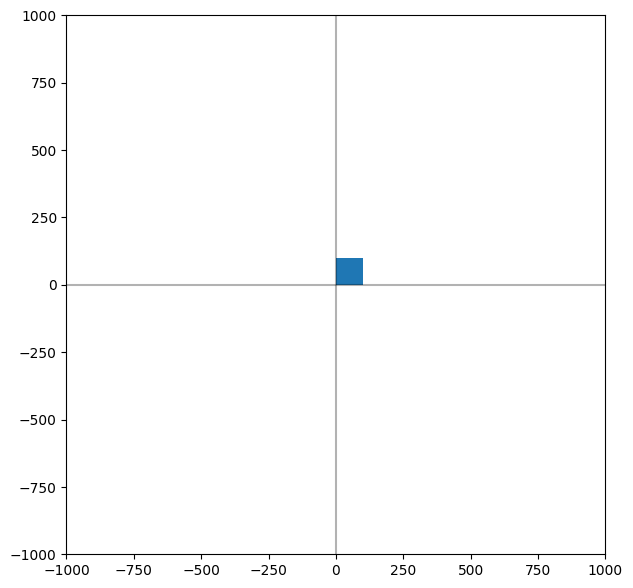

In [5]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [6]:
# 실습Zero의 print_val (Python 3 문법)
def print_val(x):
  print("Type:", type(x))
  print("Shape:", np.shape(x))
  print("값:\n", x)
  print(" ")

# 2차원 점 p -> 동차좌표 벡터 (x, y, 1)
def to_homogeneous(p):
  return np.array([p[0], p[1], 1.0])

# 동차좌표 벡터 (x, y, w) -> 2차원 점
def to_cartesian(hp):
  return np.array([hp[0] / hp[2], hp[1] / hp[2]])

# 점 p에 3x3 변환 행렬 m을 적용: q = M p
def apply(p, m):
  hp = to_homogeneous(p)     # 1. 동차좌표계로 변환
  q = np.dot(m, hp)          # 2. 행렬-벡터 곱 (3,3) x (3,1) -> (3,1)
  return to_cartesian(q)     # 3. 2차원 좌표계로 변환

# 여러 변환 행렬을 하나로 합성 (행렬-행렬 곱)
# compose(A, B, C) = A · B · C  => 점에는 C -> B -> A 순서로 적용됨
def compose(*ms):
  result = np.eye(3)
  for m in ms:
    result = np.dot(result, m)
  return result

In [7]:
# ---------- 변환 행렬 생성 ----------
# 모두 단위 행렬 np.eye(3)에서 시작해 필요한 원소만 바꿈

def make_translate(dx, dy):    # [[1,0,dx],[0,1,dy],[0,0,1]]
  m = np.eye(3)
  m[0, 2] = dx
  m[1, 2] = dy
  return m

def make_rotate(theta):        # [[cos,-sin,0],[sin,cos,0],[0,0,1]]
  m = np.eye(3)
  m[0, 0], m[0, 1] = np.cos(theta), -np.sin(theta)
  m[1, 0], m[1, 1] = np.sin(theta),  np.cos(theta)
  return m

def make_scale(sx, sy):        # [[sx,0,0],[0,sy,0],[0,0,1]]
  m = np.eye(3)
  m[0, 0] = sx
  m[1, 1] = sy
  return m

def make_shear_x(sx):          # x' = x + sx*y
  m = np.eye(3)
  m[0, 1] = sx
  return m

def make_shear_y(sy):          # y' = y + sy*x
  m = np.eye(3)
  m[1, 0] = sy
  return m

def make_reflect_x():          # x축 대칭: (x, y) -> (x, -y)
  return make_scale(1, -1)

def make_reflect_y():          # y축 대칭: (x, y) -> (-x, y)
  return make_scale(-1, 1)

def make_reflect_origin():     # 원점 대칭: (x, y) -> (-x, -y)
  return make_scale(-1, -1)

def make_reflect_yx():         # y=x 대칭: (x, y) -> (y, x)
  m = np.eye(3)
  m[[0, 1]] = m[[1, 0]]        # 단위 행렬의 0행, 1행을 교환
  return m

In [8]:
# ---------- 점 변환 함수 ----------
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p
def translate(p, dx, dy):
  return apply(p, make_translate(dx, dy))

# 점 p를 원점 기준으로 theta(라디안)만큼 반시계 방향 회전: q = R(theta) p
def rotate(p, theta):
  return apply(p, make_rotate(theta))

# 점 p를 원점 기준으로 x축 sx배, y축 sy배 확대/축소: q = S(sx, sy) p
def scale(p, sx, sy):
  return apply(p, make_scale(sx, sy))

# x축 방향 기울기: q = Sh_x(sx) p
def shear_x(p, sx):
  return apply(p, make_shear_x(sx))

# y축 방향 기울기: q = Sh_y(sy) p
def shear_y(p, sy):
  return apply(p, make_shear_y(sy))

# x축 대칭: q = Rf_x p
def reflect_x(p):
  return apply(p, make_reflect_x())

# y축 대칭: q = Rf_y p
def reflect_y(p):
  return apply(p, make_reflect_y())

# 원점 대칭: q = Rf_o p
def reflect_origin(p):
  return apply(p, make_reflect_origin())

# y=x 대칭: q = Rf_yx p
def reflect_yx(p):
  return apply(p, make_reflect_yx())

In [9]:
p = np.array([3.0, 4.0])
print("translate(5, -2):", translate(p, 5, -2))      # [8, 2]
print("rotate(pi/2)    :", np.round(rotate(p, np.pi/2), 6))  # [-4, 3]
print("scale(2, 3)     :", scale(p, 2, 3))           # [6, 12]
print("shear_x(0.5)    :", shear_x(p, 0.5))          # [5, 4]
print("shear_y(0.5)    :", shear_y(p, 0.5))          # [3, 5.5]
print("reflect_x       :", reflect_x(p))             # [3, -4]
print("reflect_y       :", reflect_y(p))             # [-3, 4]
print("reflect_origin  :", reflect_origin(p))        # [-3, -4]
print("reflect_yx      :", reflect_yx(p))            # [4, 3]

# 행렬 확인 (실습Zero print_val)
print_val(make_rotate(np.pi/4))
print_val(make_reflect_yx())

# 합성 행렬 확인: R·S·T 를 한 번에 적용한 결과 == 하나씩 적용한 결과
M = compose(make_rotate(np.pi/4), make_scale(5, 5), make_translate(-50, -50))
step = rotate(scale(translate(p, -50, -50), 5, 5), np.pi/4)
print("합성 행렬 결과:", apply(p, M), " / 단계별 결과:", step)

translate(5, -2): [8. 2.]
rotate(pi/2)    : [-4.  3.]
scale(2, 3)     : [ 6. 12.]
shear_x(0.5)    : [5. 4.]
shear_y(0.5)    : [3.  5.5]
reflect_x       : [ 3. -4.]
reflect_y       : [-3.  4.]
reflect_origin  : [-3. -4.]
reflect_yx      : [4. 3.]
Type: <class 'numpy.ndarray'>
Shape: (3, 3)
값:
 [[ 0.70710678 -0.70710678  0.        ]
 [ 0.70710678  0.70710678  0.        ]
 [ 0.          0.          1.        ]]
 
Type: <class 'numpy.ndarray'>
Shape: (3, 3)
값:
 [[0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]
 
합성 행렬 결과: [  -3.53553391 -328.80465325]  / 단계별 결과: [  -3.53553391 -328.80465325]


#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [10]:
# 원점 중심으로 옮긴 사각형 네 점
def centered(p1, p2, p3, p4):
  return [translate(p, -LEN/2, -LEN/2) for p in (p1, p2, p3, p4)]

def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1, q2, q3, q4 = centered(p1, p2, p3, p4)

  # 2. 크기 변환: S(5, 5)
  s = 5
  q1, q2, q3, q4 = [scale(q, s, s) for q in (q1, q2, q3, q4)]

  # 3. 회전 변환: R(pi/4)
  q1, q2, q3, q4 = [rotate(q, np.pi/4) for q in (q1, q2, q3, q4)]

  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)


In [11]:
# 왼쪽 위 날개축 한 개 (가늘고 긴 사각형을 y방향으로 기울임)
def left_strut(p1, p2, p3, p4):
  q = centered(p1, p2, p3, p4)
  q = [scale(p, 5, 0.6) for p in q]        # 2. 크기: 폭 500, 높이 60
  q = [shear_y(p, 0.16) for p in q]        # 3. y기울기: 조종석 쪽이 위로
  q = [translate(p, -500, 60) for p in q]  # 4. 이동: x -750 ~ -250
  return q

def draw_left_arm(ax, p1, p2, p3, p4):   # 왼쪽 날개축
  upper = left_strut(p1, p2, p3, p4)
  lower = [reflect_x(p) for p in upper]   # 아래쪽 축 = 위쪽 축의 x축 대칭
  draw_rectangle(ax, *upper)
  draw_rectangle(ax, *lower)

def draw_right_arm(ax, p1, p2, p3, p4):  # 오른쪽 날개축
  upper = [reflect_y(p) for p in left_strut(p1, p2, p3, p4)]  # y축 대칭
  lower = [reflect_origin(p) for p in left_strut(p1, p2, p3, p4)]  # 원점 대칭
  draw_rectangle(ax, *upper)
  draw_rectangle(ax, *lower)

In [12]:
# 왼쪽 날개를 이루는 사각형들(몸통 + 위/아래 비스듬한 끝)의 꼭짓점 목록
def left_wing_parts(p1, p2, p3, p4):
  parts = []
  # (1) 날개 몸통: S(1, 8) -> T(-800, 0)   => x -850~-750, y -400~400
  #     변환 행렬을 np.dot으로 합성: M = T(-800, 0) · S(1, 8) · T(-LEN/2, -LEN/2)
  M = compose(make_translate(-800, 0), make_scale(1, 8), make_translate(-LEN/2, -LEN/2))
  body = [apply(p, M) for p in (p1, p2, p3, p4)]
  parts.append(body)

  # (2) 위쪽 끝: S(1, 2) -> Sh_y(-2) -> T(-800, 400)
  #     바깥쪽(x=-850)은 y=600까지, 안쪽(x=-750)은 y=400 => 비스듬히 잘린 모양
  tip = [translate(shear_y(scale(p, 1, 2), -2), -800, 400) for p in centered(p1, p2, p3, p4)]
  parts.append(tip)

  # (3) 아래쪽 끝: 위쪽 끝을 x축 대칭
  parts.append([reflect_x(p) for p in tip])
  return parts

def draw_left_wing(ax, p1, p2, p3, p4):   # 왼쪽 날개
  for part in left_wing_parts(p1, p2, p3, p4):
    draw_rectangle(ax, *part)

def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개 = 왼쪽 날개의 y축 대칭
  for part in left_wing_parts(p1, p2, p3, p4):
    draw_rectangle(ax, *[reflect_y(p) for p in part])

In [13]:
# tie fighter 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 2. 왼쪽 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)

  # 3. 왼쪽 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)

  # 4. 오른쪽 날개축 그리기
  draw_right_arm(ax, p1, p2, p3, p4)

  # 5. 오른쪽 날개 그리기
  draw_right_wing(ax, p1, p2, p3, p4)

  # 1. 중앙 조종석 그리기 (날개축 위에 보이도록 마지막에 그림)
  draw_cockpit(ax, p1, p2, p3, p4)

### 3. main

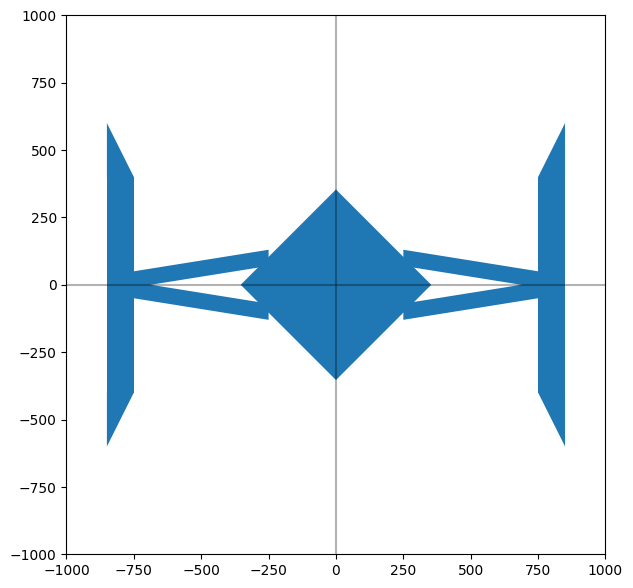

In [14]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()